# Train EfficientNetV2-S ? merged_standardized — Brain MRI Classification

This notebook trains EfficientNetV2-S ? merged_standardized and saves the best checkpoint. **Training only happens when you run cells in this notebook.**

**Prerequisites**
- Run your data-preparation notebook first.
- It must have created `merged_../prepared_data/train.csv`, `merged_../prepared_data/validation.csv`, and `merged_../prepared_data/test.csv`.
- Each CSV must contain at least the columns `filepath` and `class`.

The CSVs contain paths to the images; do not move the image dataset after creating the splits unless you update those paths.

## 1. Imports and configuration

If needed, uncomment the installation command and run it once. Pretrained weights may need to be downloaded the first time the model is created.

In [1]:
# %pip install pandas pillow matplotlib scikit-learn torch torchvision

from pathlib import Path
import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = Path("..")/("merged_prepared_data")
MODEL_DIR = Path("..")/("trained_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = DATA_DIR / "train.csv"
VAL_CSV = DATA_DIR / "validation.csv"
TEST_CSV = DATA_DIR / "test.csv"

CHECKPOINT_PATH = MODEL_DIR / "efficientnet_v2_s_merged_best.pth"
HISTORY_PATH = MODEL_DIR / "efficientnet_v2_s_merged_training_history.csv"

BATCH_SIZE = 8 if not torch.cuda.is_available() else 16; NUM_WORKERS=0
HEAD_EPOCHS = 5
FINETUNE_EPOCHS = 20

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP=device.type == "cuda"
print("GPU:",torch.cuda.get_device_name(0) if USE_AMP else "CPU")
print("Mixed precision:",USE_AMP)
print("Device:", device)
print("Batch size:", BATCH_SIZE)

c:\Users\rickv\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\rickv\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


GPU: NVIDIA GeForce RTX 4070 Laptop GPU
Mixed precision: True
Device: cuda
Batch size: 16


## 2. Load the saved splits

This notebook does not recreate or change the split. It uses the CSVs saved during data preparation.

In [2]:
for csv_path in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not csv_path.exists():
        raise FileNotFoundError(
            f"Missing {csv_path}. Run the data-preparation notebook first "
            "and check that its output folder is named 'merged_prepared_data'."
        )

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

required_columns = {"filepath", "class"}
for name, frame in [
    ("train", train_df), ("validation", val_df), ("test", test_df)
]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{name}.csv is missing columns: {sorted(missing)}")

class_names = sorted(train_df["class"].unique().tolist())
class_to_idx = {name: i for i, name in enumerate(class_names)}
idx_to_class = {i: name for name, i in class_to_idx.items()}

# Ensure all splits contain only the same four known classes.
for name, frame in [("validation", val_df), ("test", test_df)]:
    unknown = set(frame["class"].unique()) - set(class_names)
    if unknown:
        raise ValueError(f"Unexpected classes in {name}: {unknown}")

print("Classes:", class_to_idx)
print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")
display(pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "validation": val_df["class"].value_counts(),
    "test": test_df["class"].value_counts()
}).fillna(0).astype(int).sort_index())

Classes: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'normal': 2, 'pituitary_tumor': 3}
Train: 6800 | Validation: 1457 | Test: 1458


,train,validation,test
class,,,
glioma_tumor,1865,399,400
meningioma_tumor,1749,375,375
normal,1372,294,294
pituitary_tumor,1814,389,389


## 3. Create datasets and dataloaders

Training uses a small random rotation as augmentation. Validation and test images are not randomly augmented.

In [3]:
weights = EfficientNet_V2_S_Weights.DEFAULT

train_transform = transforms.Compose([
    transforms.Resize((384, 384)),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
eval_transform = weights.transforms()

class BrainMRIDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        with Image.open(row["filepath"]) as img:
            image = img.convert("RGB")
        label = class_to_idx[row["class"]]
        if self.transform:
            image = self.transform(image)
        return image, label

train_dataset = BrainMRIDataset(train_df, train_transform)
val_dataset = BrainMRIDataset(val_df, eval_transform)
test_dataset = BrainMRIDataset(test_df, eval_transform)

generator = torch.Generator().manual_seed(SEED)

loader_kwargs={"num_workers": NUM_WORKERS, "pin_memory": USE_AMP}
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,generator=generator,**loader_kwargs)
val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False,**loader_kwargs)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,**loader_kwargs)
batch_images, batch_labels = next(iter(train_loader))
print("Training batch shape:", tuple(batch_images.shape))
print("Label batch shape:", tuple(batch_labels.shape))

Training batch shape: (16, 3, 384, 384)
Label batch shape: (16,)


## 4. Build EfficientNetV2-S ? merged_standardized

The pretrained feature extractor is initially frozen. The first phase trains only the final classification layer; the second phase fine-tunes the full network.

In [4]:
model = efficientnet_v2_s(weights=weights)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, len(class_names)
)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)


## 5. Training loop

Run this cell to train. It saves a checkpoint whenever validation loss improves. Re-running this cell will train again, so run it only when you intend to retrain.

In [5]:
model=efficientnet_v2_s(weights=weights)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))
model=model.to(device)
criterion=nn.CrossEntropyLoss()
scaler=torch.cuda.amp.GradScaler(enabled=USE_AMP)

history=[]
best_val_loss=float("inf")
best_model_weights=None
PATIENCE=5
HEAD_EPOCHS=5
FINETUNE_EPOCHS=20

def run_training_phase(optimizer,max_epochs,phase_name):
    global best_val_loss,best_model_weights
    phase_best_val_loss=float("inf")
    epochs_without_improvement=0
    for epoch in range(max_epochs):
        epoch_start=time.perf_counter()
        data_wait=0.0; compute_time=0.0
        model.train(); train_loss_sum=train_correct=train_count=0
        batch_start=time.perf_counter()
        for images,labels in train_loader:
            data_wait += time.perf_counter()-batch_start
            compute_start=time.perf_counter()
            images=images.to(device,non_blocking=USE_AMP); labels=labels.to(device,non_blocking=USE_AMP)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=USE_AMP):
                outputs=model(images); loss=criterion(outputs,labels)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            if USE_AMP: torch.cuda.synchronize()
            compute_time += time.perf_counter()-compute_start
            train_loss_sum += loss.item()*labels.size(0); train_correct += (outputs.argmax(dim=1)==labels).sum().item(); train_count += labels.size(0)
            batch_start=time.perf_counter()
        train_loss=train_loss_sum/train_count; train_accuracy=train_correct/train_count
        validation_start=time.perf_counter()
        model.eval(); val_loss_sum=val_correct=val_count=0
        with torch.no_grad():
            for images,labels in val_loader:
                images=images.to(device,non_blocking=USE_AMP); labels=labels.to(device,non_blocking=USE_AMP)
                with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=USE_AMP):
                    outputs=model(images); loss=criterion(outputs,labels)
                val_loss_sum += loss.item()*labels.size(0); val_correct += (outputs.argmax(dim=1)==labels).sum().item(); val_count += labels.size(0)
        if USE_AMP: torch.cuda.synchronize()
        validation_time=time.perf_counter()-validation_start
        val_loss=val_loss_sum/val_count; val_accuracy=val_correct/val_count
        improved=val_loss < phase_best_val_loss; checkpoint_time=0.0
        if improved:
            phase_best_val_loss=val_loss; epochs_without_improvement=0
            if val_loss < best_val_loss:
                best_val_loss=val_loss
                best_model_weights={key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
                save_start=time.perf_counter()
                torch.save({"model_state_dict":best_model_weights,"class_names":class_names,"class_to_idx":class_to_idx,"architecture":"efficientnet_v2_s","input_size":384,"best_val_loss":best_val_loss,"seed":SEED},CHECKPOINT_PATH)
                checkpoint_time=time.perf_counter()-save_start
        else: epochs_without_improvement += 1
        epoch_time=time.perf_counter()-epoch_start
        gpu_memory=torch.cuda.max_memory_allocated()/1024**3 if USE_AMP else 0.0
        history.append({"phase":phase_name,"epoch":epoch+1,"train_loss":train_loss,"train_accuracy":train_accuracy,"val_loss":val_loss,"val_accuracy":val_accuracy,"best":improved,"epochs_without_improvement":epochs_without_improvement,"data_wait_seconds":data_wait,"compute_seconds":compute_time,"validation_seconds":validation_time,"checkpoint_seconds":checkpoint_time,"epoch_seconds":epoch_time,"peak_gpu_memory_gb":gpu_memory})
        print(f"{phase_name} | Epoch {epoch+1}/{max_epochs} | train {train_loss:.4f}/{train_accuracy:.4f} | val {val_loss:.4f}/{val_accuracy:.4f} | data {data_wait:.1f}s | compute {compute_time:.1f}s | val {validation_time:.1f}s | save {checkpoint_time:.2f}s | total {epoch_time:.1f}s | VRAM {gpu_memory:.2f}GB | patience {epochs_without_improvement}/{PATIENCE}")
        if USE_AMP: torch.cuda.reset_peak_memory_stats()
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping {phase_name} after {epoch+1} epochs."); break

for parameter in model.parameters(): parameter.requires_grad=False
for parameter in model.classifier.parameters(): parameter.requires_grad=True
head_optimizer=optim.AdamW(model.classifier.parameters(),lr=1e-3,weight_decay=1e-4)
run_training_phase(head_optimizer,HEAD_EPOCHS,"Frozen backbone")
if best_model_weights is not None: model.load_state_dict(best_model_weights,strict=True)
for parameter in model.parameters(): parameter.requires_grad=True
finetune_optimizer=optim.AdamW(model.parameters(),lr=1e-4,weight_decay=1e-4)
run_training_phase(finetune_optimizer,FINETUNE_EPOCHS,"Fine-tuning")
if best_model_weights is not None: model.load_state_dict(best_model_weights,strict=True)
pd.DataFrame(history).to_csv(HISTORY_PATH,index=False)
print("Training finished.")
print("Best checkpoint:",CHECKPOINT_PATH.resolve())
print("Training history:",HISTORY_PATH.resolve())


C:\Users\rickv\AppData\Local\Temp\ipykernel_20660\2647345660.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler=torch.cuda.amp.GradScaler(enabled=USE_AMP)


Frozen backbone | Epoch 1/5 | train 0.7953/0.7079 | val 0.5496/0.8202 | data 25.8s | compute 17.1s | val 10.0s | save 0.07s | total 53.2s | VRAM 0.28GB | patience 0/5
Frozen backbone | Epoch 2/5 | train 0.6067/0.7787 | val 0.5071/0.8367 | data 27.7s | compute 17.5s | val 10.5s | save 0.07s | total 56.0s | VRAM 0.28GB | patience 0/5
Frozen backbone | Epoch 3/5 | train 0.5645/0.7884 | val 0.4369/0.8415 | data 25.1s | compute 16.6s | val 9.4s | save 0.06s | total 51.4s | VRAM 0.28GB | patience 0/5
Frozen backbone | Epoch 4/5 | train 0.5300/0.8069 | val 0.4395/0.8463 | data 24.5s | compute 16.2s | val 9.5s | save 0.00s | total 50.3s | VRAM 0.28GB | patience 1/5
Frozen backbone | Epoch 5/5 | train 0.5362/0.8056 | val 0.3954/0.8668 | data 23.8s | compute 16.0s | val 9.4s | save 0.06s | total 49.5s | VRAM 0.28GB | patience 0/5
Fine-tuning | Epoch 1/20 | train 0.2751/0.9053 | val 0.0682/0.9787 | data 25.3s | compute 58.2s | val 9.6s | save 0.07s | total 93.3s | VRAM 3.72GB | patience 0/5
Fine-

## 6. View training history

This plots the history from the current run. It does not train the model.

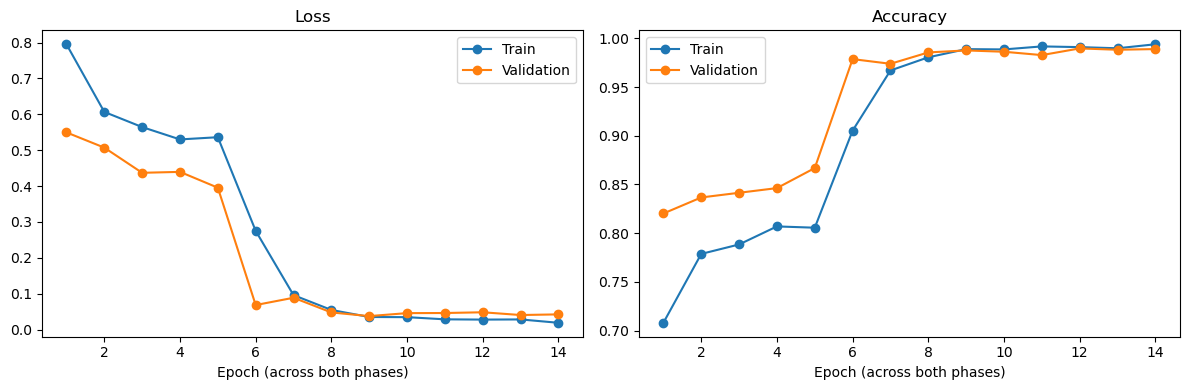

In [6]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df.index + 1, history_df["train_loss"], marker="o", label="Train")
axes[0].plot(history_df.index + 1, history_df["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch (across both phases)")
axes[0].legend()

axes[1].plot(history_df.index + 1, history_df["train_accuracy"], marker="o", label="Train")
axes[1].plot(history_df.index + 1, history_df["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch (across both phases)")
axes[1].legend()

plt.tight_layout()
plt.show()